# Clase 6 parte 1: datos y análisis exploratorio

Tu primera responsabilidad es preparar una fuente de datos confiable para el proyecto de clasificación de vinos.

**Entrada:** `data/raw/wine.csv`  
**Salidas:** `data/processed/train.csv`, `data/processed/test.csv` y `artifacts/data_contract.json`

> El conjunto de test se crea aquí, pero no debe explorarse ni utilizarse después del split.

**Autor: Jaime Andrés Jaramillo Ramírez.**

Ejecutar las partes 1, 2 y 3 en ese orden, desde la misma carpeta (o la subcarpeta `notebooks`). Dependencias: numpy, pandas, matplotlib, seaborn, scikit-learn y joblib. En Colab, usar el mismo entorno de ejecución para conservar los archivos entre partes.

**Fuente:** no se adjuntó el CSV de clase. La parte 1 usa `data/raw/wine.csv` si existe; de lo contrario exporta el dataset Wine incluido en scikit-learn. Los resultados guardados corresponden a esta alternativa y deben recalcularse si se usa otro CSV.

## Objetivos

- cargar y validar datos externos;
- identificar problemas básicos de calidad;
- crear un split reproducible y estratificado;
- realizar EDA únicamente sobre entrenamiento;
- guardar datos y metadatos para la siguiente etapa.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

np.random.seed(42)
plt.rcParams["figure.figsize"] = (7, 4)

In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent
RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42


## 1. Carga y profiling

In [3]:
DATA_PATH = RAW_DATA_DIR / "wine.csv"
if not DATA_PATH.exists():
    from sklearn.datasets import load_wine
    RAW_DATA_DIR.mkdir(parents=True, exist_ok=True)
    load_wine(as_frame=True).frame.to_csv(DATA_PATH, index=False)
    print("No se encontró el CSV de clase: se exportó Wine de sklearn como alternativa.")
    source = "sklearn.datasets.load_wine (alternativa al CSV no adjuntado)"
else:
    source = "CSV local: data/raw/wine.csv; verificar procedencia con el docente"
df = pd.read_csv(DATA_PATH)
if not df.columns.is_unique or "target" not in df:
    raise ValueError("Se requieren columnas únicas y una columna target.")
if df.empty or len(df.columns) < 2:
    raise ValueError("El archivo debe contener registros y predictores.")
print("Fuente:", source)
display(df.head())


No se encontró el CSV de clase: se exportó Wine de sklearn como alternativa.
Fuente: sklearn.datasets.load_wine (alternativa al CSV no adjuntado)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [4]:
print("Forma original:", df.shape)
display(pd.DataFrame({"tipo": df.dtypes.astype(str), "nulos": df.isna().sum()}))
print("Duplicados completos:", int(df.duplicated().sum()))
display(df["target"].value_counts(dropna=False).rename("registros").to_frame())
original_rows = len(df)
# Una misma observación no debe aparecer en train y test.
df = df.drop_duplicates().dropna(subset=["target"]).copy()
features = df.columns.drop("target").tolist()
if not all(pd.api.types.is_numeric_dtype(df[c]) for c in features):
    raise ValueError("Los predictores deben ser numéricos; revisar el CSV.")
if np.isinf(df[features].to_numpy(dtype=float)).any():
    raise ValueError("Hay infinitos: corregir su origen antes de continuar.")
if df[features].isna().all().any():
    raise ValueError("Hay predictores completamente vacíos.")
if df["target"].nunique() < 2 or df["target"].value_counts().min() < 2:
    raise ValueError("No hay suficientes clases/observaciones para estratificar.")
print("Filas retiradas (duplicados o target ausente):", original_rows-len(df))
print("Los nulos de predictores, si existen, se imputarán dentro de cada fold.")


Forma original: (178, 14)


,tipo,nulos
alcohol,float64,0
malic_acid,float64,0
ash,float64,0
alcalinity_of_ash,float64,0
magnesium,float64,0
total_phenols,float64,0
flavanoids,float64,0
nonflavanoid_phenols,float64,0
proanthocyanins,float64,0
color_intensity,float64,0


Duplicados completos: 0


,registros
target,
1,71
0,59
2,48


Filas retiradas (duplicados o target ausente): 0
Los nulos de predictores, si existen, se imputarán dentro de cada fold.


**Conclusión de calidad:** en el Wine utilizado hay 178 observaciones, 13 predictores numéricos y tres clases (59, 71 y 48 registros). No se encontraron nulos ni duplicados, por lo que se conservaron todas las filas. La clase 1 es la más frecuente, pero ninguna domina de forma extrema. Se estratifica la partición para conservar aproximadamente las proporciones. Los valores extremos no se eliminan automáticamente: podrían representar diferencias reales entre vinos. La imputación se reserva para el pipeline de entrenamiento, evitando aprender estadísticas del test.


## 2. Split train/test

In [5]:
train_df, test_df = train_test_split(
    df, test_size=0.20, stratify=df["target"], random_state=RANDOM_STATE
)


In [6]:
# Verificación del split
assert len(train_df) + len(test_df) == len(df)
assert set(train_df.index).isdisjoint(set(test_df.index))
print("Train:", train_df.shape)
print("Test:", test_df.shape)

Train: (142, 14)
Test: (36, 14)


## 3. EDA sobre entrenamiento

Incluye:

- distribución de clases;
- distribuciones o boxplots de variables relevantes;
- correlaciones;
- tres hallazgos que puedan influir en el modelado.

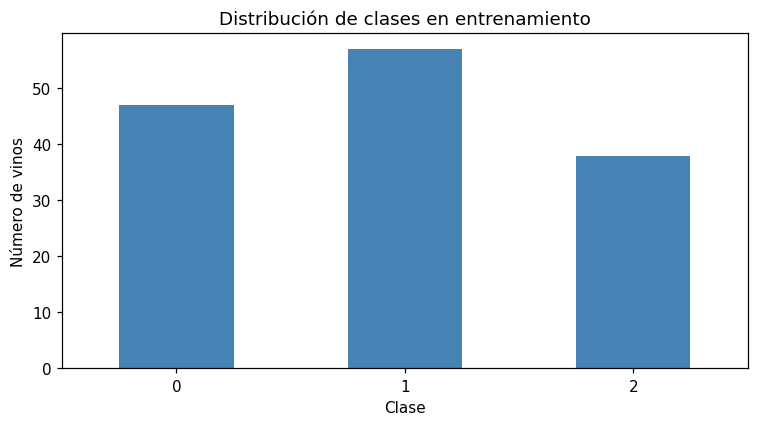

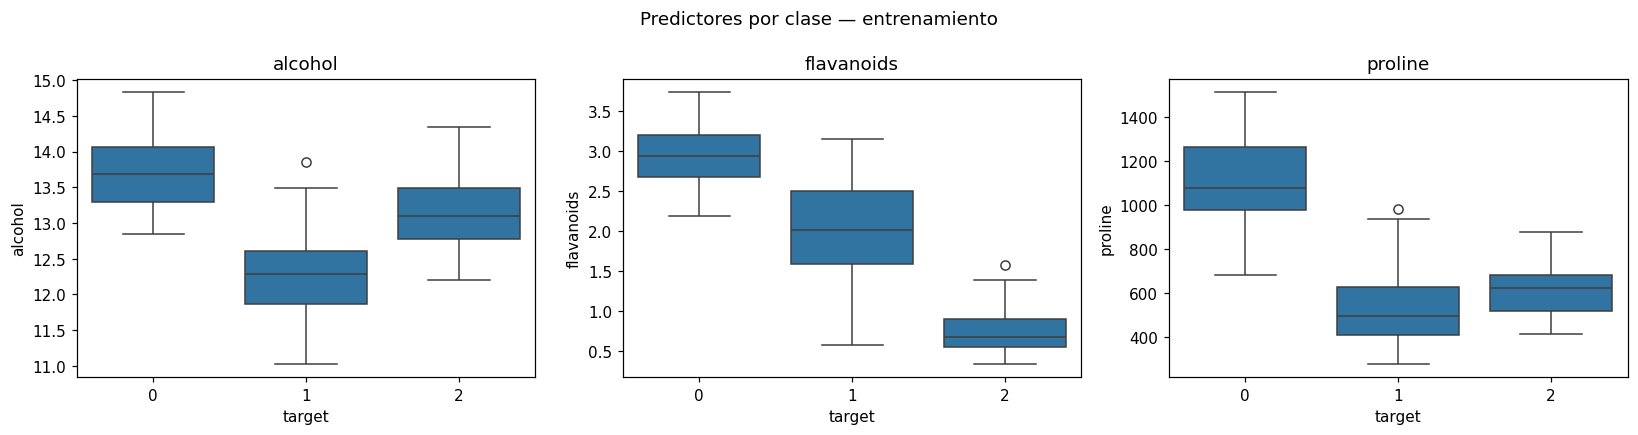

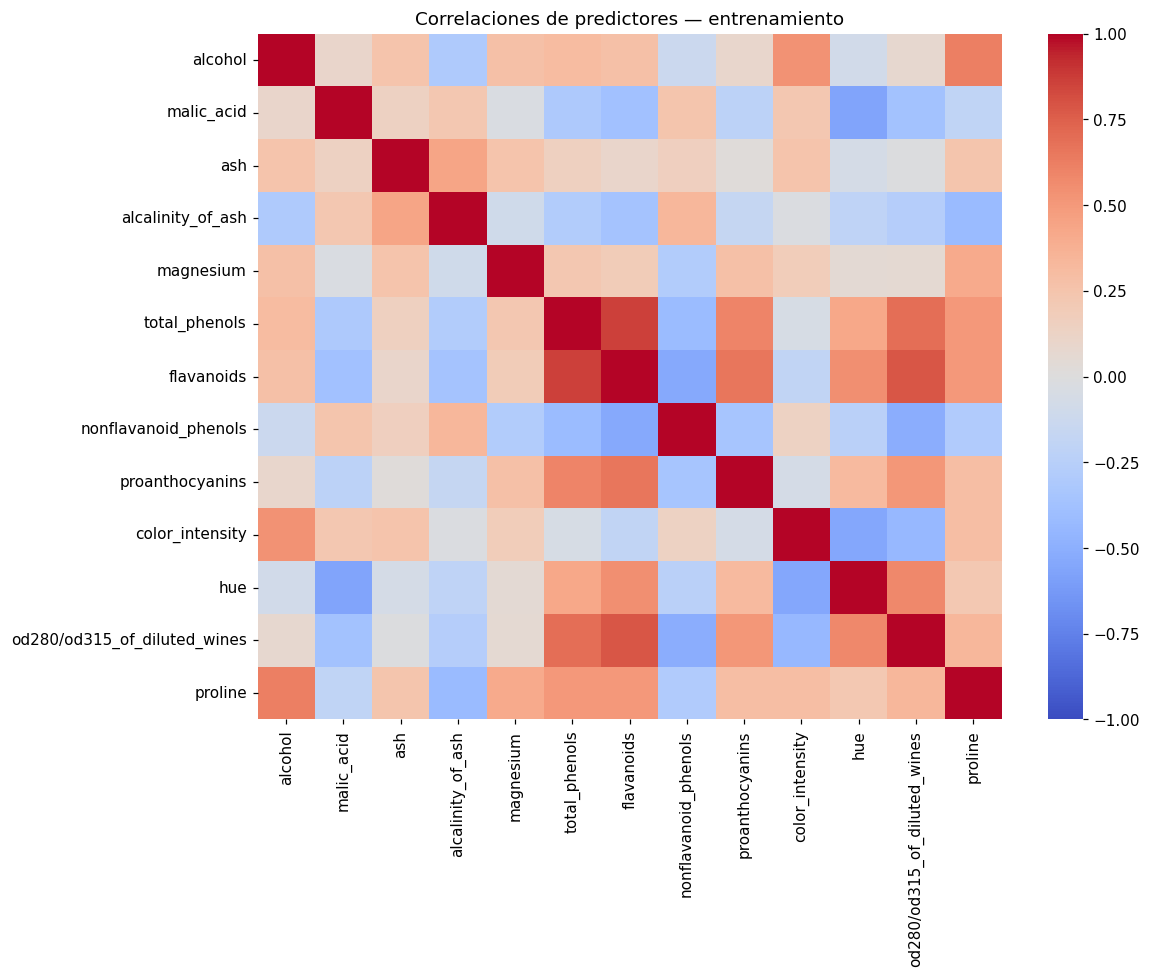

,mean,std,min,max
alcohol,12.971479,0.802521,11.03,14.83
malic_acid,2.340000,1.101285,0.74,5.80
ash,2.364859,0.268380,1.36,3.22
alcalinity_of_ash,19.625352,3.380848,10.60,30.00
magnesium,99.633803,14.937448,70.00,162.00
total_phenols,2.273732,0.621454,0.98,3.88
flavanoids,1.985352,0.951952,0.34,3.74
nonflavanoid_phenols,0.360141,0.119211,0.13,0.63
proanthocyanins,1.600211,0.579777,0.42,3.58
color_intensity,4.989648,2.334947,1.28,13.00


Correlaciones más fuertes (valor absoluto):


,,correlación
total_phenols,flavanoids,0.860927
flavanoids,od280/od315_of_diluted_wines,0.786320
total_phenols,od280/od315_of_diluted_wines,0.694710
flavanoids,proanthocyanins,0.657046
alcohol,proline,0.620742


In [7]:
# Todas las gráficas y estadísticas siguientes utilizan solamente train.
train_df["target"].value_counts().sort_index().plot.bar(color="steelblue")
plt.title("Distribución de clases en entrenamiento")
plt.xlabel("Clase"); plt.ylabel("Número de vinos"); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()
relevant = [c for c in ["alcohol", "flavanoids", "proline"] if c in features]
if not relevant:
    relevant = features[:3]
fig, axes = plt.subplots(1, len(relevant), figsize=(5*len(relevant), 4), squeeze=False)
for ax, col in zip(axes.ravel(), relevant):
    sns.boxplot(data=train_df, x="target", y=col, ax=ax)
    ax.set_title(col)
fig.suptitle("Predictores por clase — entrenamiento")
plt.tight_layout(); plt.show()
corr = train_df[features].corr()
plt.figure(figsize=(11, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlaciones de predictores — entrenamiento")
plt.tight_layout(); plt.show()
display(train_df[features].agg(["mean", "std", "min", "max"]).T)
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
print("Correlaciones más fuertes (valor absoluto):")
display(upper.loc[upper.abs().sort_values(ascending=False).head(5).index].to_frame("correlación"))


**Hallazgos del entrenamiento (Wine de sklearn):**

1. Los predictores tienen escalas distintas: `proline` se mide en cientos, mientras que otras variables presentan valores pequeños. Se estandarizarán las entradas para KNN y regresión logística para que la escala no determine las distancias o la regularización.
2. `flavanoids` y `total_phenols` presentan una asociación positiva fuerte. Hay información compartida; una regresión logística regularizada puede manejar esta redundancia, aunque los coeficientes no deben interpretarse como efectos causales.
3. Los boxplots de `alcohol`, `flavanoids` y `proline` muestran diferencias entre clases, pero también dispersión y solapamiento. Se comparan un modelo lineal y modelos no lineales mediante CV estratificada, sin decidir con base en test.


## 4. Persistencia de datos y contrato

In [8]:
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)
train_df.to_csv(PROCESSED_DATA_DIR / "train.csv", index=False)
test_df.to_csv(PROCESSED_DATA_DIR / "test.csv", index=False)
contract = {
    "target": "target", "features": features,
    "random_state": RANDOM_STATE, "test_size": 0.20,
    "source": source, "n_train": len(train_df), "n_test": len(test_df),
    "feature_dtypes": {c: str(train_df[c].dtype) for c in features},
    "classes": sorted(train_df["target"].unique().tolist()),
    "missing_policy": "median fitted inside each training fold",
}
(ARTIFACTS_DIR / "data_contract.json").write_text(
    json.dumps(contract, indent=2, ensure_ascii=False), encoding="utf-8"
)
print("Datos y contrato guardados.")


Datos y contrato guardados.


In [9]:
# Verificación de entrega
assert (PROCESSED_DATA_DIR / "train.csv").exists()
assert (PROCESSED_DATA_DIR / "test.csv").exists()
assert (ARTIFACTS_DIR / "data_contract.json").exists()
print("Challenge 1 completado.")

Challenge 1 completado.


## Checklist

- [x] Cargué el CSV desde `data/raw`.
- [x] Revisé calidad y distribución de la clase.
- [x] Realicé un split estratificado.
- [x] No exploré el conjunto de test.
- [x] Guardé los tres artefactos requeridos.